Dataset : MERFISH Mouse Brain Receptor Map

URL = https://info.vizgen.com/mouse-brain-map?submissionGuid=a9558758-2355-454e-96c2-6f6c07626bc8

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
sns.set_theme(style="whitegrid", context="notebook")

DATA_DIR = "../Dataset/MERFISH/mouse_brain_map/Slice1/Replicate1"

EXPR_FILE = DATA_DIR + "/cell_by_gene_S1R1.csv"
META_FILE = DATA_DIR + "/cell_metadata_S1R1.csv"
TRANSCRIPT_FILE = DATA_DIR + "/detected_transcripts_S1R1.csv"

In [5]:
# Load the cell-level expression matrix and metadata
expr = pd.read_csv(EXPR_FILE)
meta = pd.read_csv(META_FILE)

print("Expression matrix shape:", expr.shape)
print("Cell metadata shape:", meta.shape)

print("\nExpression matrix columns:")
print(expr.columns.tolist()[:20])

print("\nMetadata columns:")
print(meta.columns.tolist())

print("\nExpression matrix preview:")
display(expr.head())

print("\nMetadata preview:")
display(meta.head())

Expression matrix shape: (78329, 650)
Cell metadata shape: (78329, 9)

Expression matrix columns:
['Unnamed: 0', 'Oxgr1', 'Htr1a', 'Htr1b', 'Htr1d', 'Htr1f', 'Htr2a', 'Htr2b', 'Htr2c', 'Htr4', 'Htr5a', 'Htr5b', 'Htr6', 'Htr7', 'Adora1', 'Adora2a', 'Adora2b', 'Adora3', 'Adgra1', 'Adgra2']

Metadata columns:
['Unnamed: 0', 'fov', 'volume', 'center_x', 'center_y', 'min_x', 'max_x', 'min_y', 'max_y']

Expression matrix preview:


,Unnamed: 0,Oxgr1,Htr1a,Htr1b,Htr1d,Htr1f,Htr2a,Htr2b,Htr2c,Htr4,...,Blank-156,Blank-157,Blank-158,Blank-159,Blank-160,Blank-161,Blank-162,Blank-163,Blank-164,Blank-165
0,110883424764611924400221639916314253469,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,135188247894899244046039873973964001182,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,164766962839370328502017156371562646881,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,165747897693809971960756442245389760838,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,260943245639750847364278545493286724628,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0



Metadata preview:


,Unnamed: 0,fov,volume,center_x,center_y,min_x,max_x,min_y,max_y
0,110883424764611924400221639916314253469,0,432.141425,156.563284,4271.326432,151.530484,161.596084,4264.619632,4278.033232
1,135188247894899244046039873973964001182,0,1351.802616,156.509284,4256.962431,148.290484,164.728084,4247.663631,4266.261232
2,164766962839370328502017156371562646881,0,1080.653268,159.965284,4228.180431,152.178484,167.752084,4220.555630,4235.805231
3,165747897693809971960756442245389760838,0,1652.000749,167.579284,4323.868433,158.226484,176.932084,4314.191633,4333.545233
4,260943245639750847364278545493286724628,0,1343.378642,160.559284,4308.802433,152.394484,168.724084,4301.231633,4316.373233


In [6]:
print(f"Expression matrix: {expr.shape[0]:,} rows × {expr.shape[1]:,} columns")
print(f"Metadata: {meta.shape[0]:,} rows × {meta.shape[1]:,} columns")

print("\nMissing values in expression data:", expr.isna().sum().sum())
print("Missing values in metadata:", meta.isna().sum().sum())

Expression matrix: 78,329 rows × 650 columns
Metadata: 78,329 rows × 9 columns

Missing values in expression data: 0
Missing values in metadata: 0


In [8]:
# Detect a likely cell-ID column
id_candidates = ["cell_id", "CellID", "cellID", "cell", "id", "Unnamed: 0"]

expr_id = next(
    (c for c in id_candidates if c in expr.columns), None
)
meta_id = next(
    (c for c in id_candidates if c in meta.columns), None
)

print("Expression cell ID:", expr_id)
print("Metadata cell ID:", meta_id)

# If IDs are present in both files, compare them
if expr_id and meta_id:
    expr_ids = set(expr[expr_id].astype(str))
    meta_ids = set(meta[meta_id].astype(str))

    print("IDs shared between files:", len(expr_ids & meta_ids))
    print("Expression IDs without metadata:", len(expr_ids - meta_ids))
    print("Metadata IDs without expression:", len(meta_ids - expr_ids))

Expression cell ID: Unnamed: 0
Metadata cell ID: Unnamed: 0
IDs shared between files: 78329
Expression IDs without metadata: 0
Metadata IDs without expression: 0


X coordinate: center_x
Y coordinate: center_y


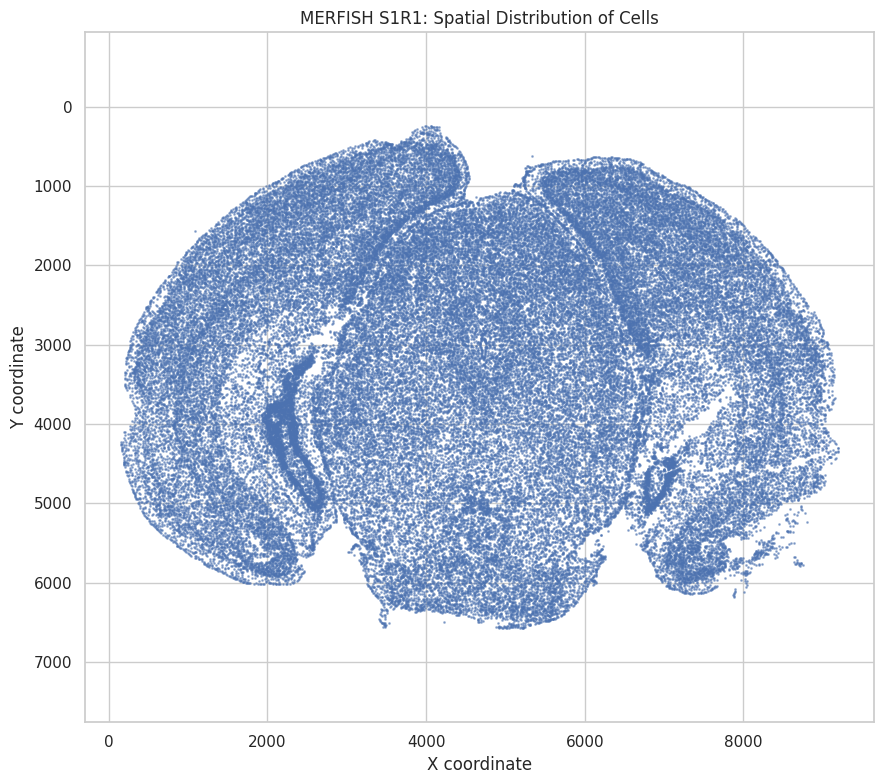

In [9]:
# Find likely coordinate columns
def find_column(columns, candidates):
    lower_to_original = {str(c).lower(): c for c in columns}
    for name in candidates:
        if name.lower() in lower_to_original:
            return lower_to_original[name.lower()]
    return None

x_col = find_column(
    meta.columns,
    ["center_x", "global_x", "x", "centerx", "x_centroid"]
)
y_col = find_column(
    meta.columns,
    ["center_y", "global_y", "y", "centery", "y_centroid"]
)

print("X coordinate:", x_col)
print("Y coordinate:", y_col)

if x_col is None or y_col is None:
    print("Coordinates not detected. Inspect metadata columns above.")
else:
    spatial = meta[[x_col, y_col]].copy()
    spatial.columns = ["x", "y"]
    spatial = spatial.dropna()

    plt.figure(figsize=(9, 8))
    plt.scatter(
        spatial["x"],
        spatial["y"],
        s=1,
        alpha=0.5,
        rasterized=True
    )
    plt.gca().invert_yaxis()
    plt.xlabel("X coordinate")
    plt.ylabel("Y coordinate")
    plt.title("MERFISH S1R1: Spatial Distribution of Cells")
    plt.axis("equal")
    plt.tight_layout()
    plt.show()

Number of gene columns: 649
Median counts per cell: 269.0
Median genes detected per cell: 74.0


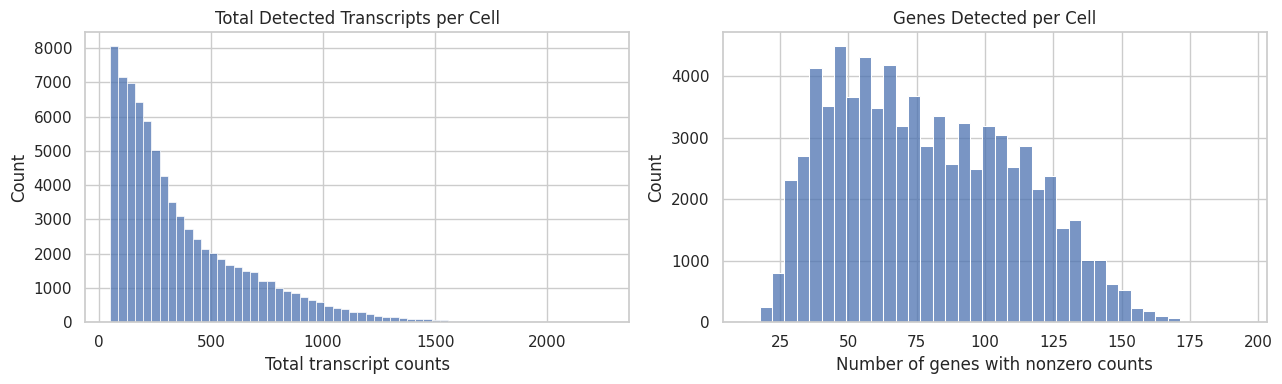

In [10]:
# Select gene columns
exclude_cols = {expr_id} if expr_id else set()
gene_cols = [c for c in expr.columns if c not in exclude_cols]

# Convert gene-expression values to numeric
counts = expr[gene_cols].apply(pd.to_numeric, errors="coerce").fillna(0)

# Basic cell-level quality metrics
total_counts = counts.sum(axis=1)
genes_detected = (counts > 0).sum(axis=1)

print("Number of gene columns:", len(gene_cols))
print("Median counts per cell:", total_counts.median())
print("Median genes detected per cell:", genes_detected.median())

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(total_counts, bins=60, ax=axes[0])
axes[0].set_title("Total Detected Transcripts per Cell")
axes[0].set_xlabel("Total transcript counts")

sns.histplot(genes_detected, bins=40, ax=axes[1])
axes[1].set_title("Genes Detected per Cell")
axes[1].set_xlabel("Number of genes with nonzero counts")

plt.tight_layout()
plt.show()

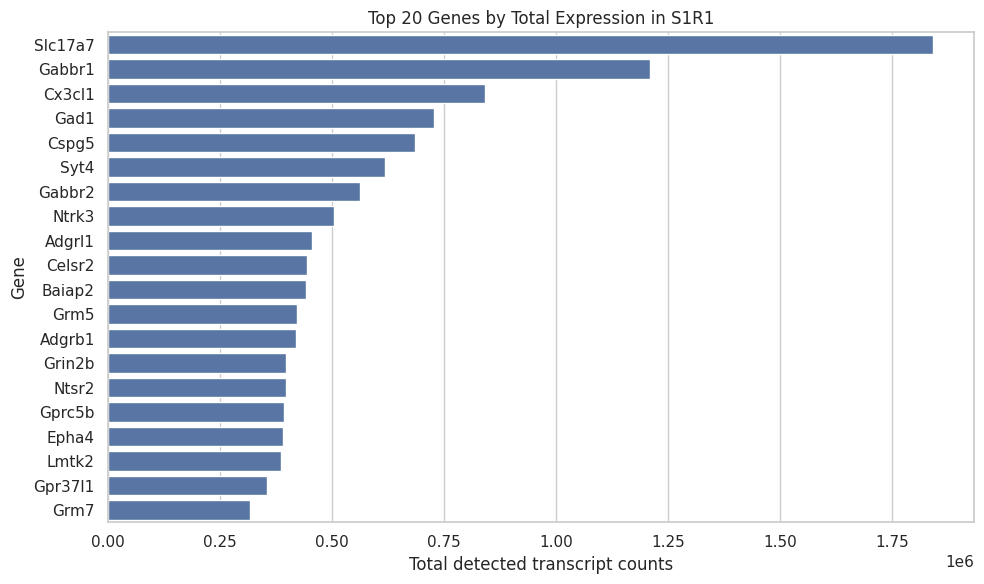

Slc17a7    1840029.0
Gabbr1     1210198.0
Cx3cl1      841360.0
Gad1        727069.0
Cspg5       684129.0
Syt4        618693.0
Gabbr2      561271.0
Ntrk3       503324.0
Adgrl1      456103.0
Celsr2      445023.0
Baiap2      441706.0
Grm5        421641.0
Adgrb1      419587.0
Grin2b      396500.0
Ntsr2       396181.0
Gprc5b      391824.0
Epha4       391177.0
Lmtk2       386393.0
Gpr37l1     355344.0
Grm7        316645.0
dtype: float64


In [11]:
gene_totals = counts.sum(axis=0).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(
    x=gene_totals.head(20).values,
    y=gene_totals.head(20).index,
    orient="h"
)
plt.xlabel("Total detected transcript counts")
plt.ylabel("Gene")
plt.title("Top 20 Genes by Total Expression in S1R1")
plt.tight_layout()
plt.show()

print(gene_totals.head(20))

Merged data shape: (78329, 658)
Visualizing gene: Gad1


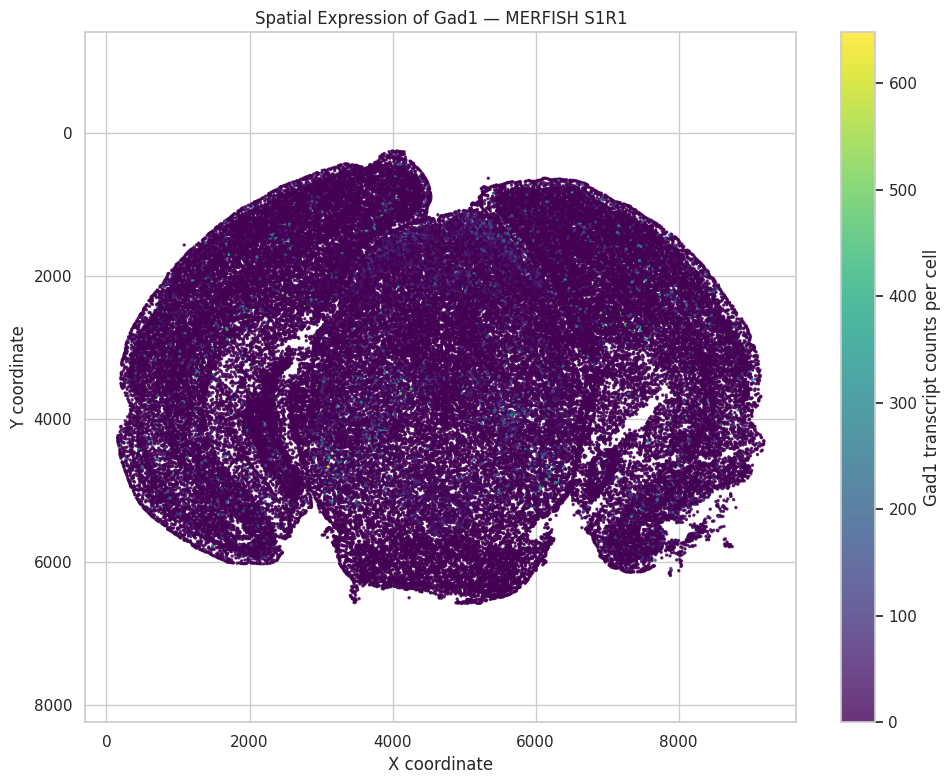

In [12]:
# Make sure IDs are available before joining
if expr_id and meta_id:
    expr_for_join = expr.copy()
    meta_for_join = meta.copy()

    expr_for_join[expr_id] = expr_for_join[expr_id].astype(str)
    meta_for_join[meta_id] = meta_for_join[meta_id].astype(str)

    merged = meta_for_join.merge(
        expr_for_join,
        left_on=meta_id,
        right_on=expr_id,
        how="inner",
        validate="one_to_one"
    )
else:
    raise ValueError(
        "Cell IDs were not detected in both files. "
        "Inspect the column names and identify the correct cell ID columns."
    )

print("Merged data shape:", merged.shape)

# Choose a gene that exists in this dataset
available_genes = [g for g in gene_cols if g in merged.columns]

# Prefer these example genes if present
preferred = ["Gad1", "Slc17a7", "Snap25", "Gfap"]
gene = next((g for g in preferred if g in available_genes),
            available_genes[0])

print("Visualizing gene:", gene)

plot_data = merged[[x_col, y_col, gene]].copy()
plot_data.columns = ["x", "y", "expression"]
plot_data = plot_data.dropna()

plt.figure(figsize=(10, 8))
sc = plt.scatter(
    plot_data["x"],
    plot_data["y"],
    c=plot_data["expression"],
    s=2,
    cmap="viridis",
    alpha=0.8,
    rasterized=True
)
plt.gca().invert_yaxis()
plt.axis("equal")
plt.colorbar(sc, label=f"{gene} transcript counts per cell")
plt.xlabel("X coordinate")
plt.ylabel("Y coordinate")
plt.title(f"Spatial Expression of {gene} — MERFISH S1R1")
plt.tight_layout()
plt.show()

In [13]:
transcript_sample = pd.read_csv(
    TRANSCRIPT_FILE,
    nrows=100_000
)

print("Transcript columns:")
print(transcript_sample.columns.tolist())

display(transcript_sample.head())

Transcript columns:
['Unnamed: 0', 'barcode_id', 'global_x', 'global_y', 'global_z', 'x', 'y', 'fov', 'gene']


,Unnamed: 0,barcode_id,global_x,global_y,global_z,x,y,fov,gene
0,0,2,159.97784,4208.4683,4.0,1762.1163,159.98138,0,Htr1b
1,1,2,165.94028,4321.8047,4.0,1817.3240,1209.39220,0,Htr1b
2,2,11,158.47667,4320.9014,5.0,1748.2166,1201.02830,0,Htr6
3,3,13,171.21793,4283.9500,0.0,1866.1912,858.88550,0,Adora1
4,4,13,158.02158,4257.5470,1.0,1744.0027,614.41070,0,Adora1


## Preparing AnnData

In [16]:
from pathlib import Path
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy import sparse
import os

In [ ]:
# Change this if your files are stored elsewhere.

DATA = "../Dataset/MERFISH/mouse_brain_map/Slice1/Replicate1"
OUT = DATA + "/STI_results"
os.makedirs(OUT, exist_ok=True)


expr = pd.read_csv(DATA + "/cell_by_gene_S1R1.csv")
meta = pd.read_csv(DATA + "/cell_metadata_S1R1.csv")

expr = expr.rename(columns={'Unnamed: 0': "cell_id"})
meta = meta.rename(columns={'Unnamed: 0': "cell_id"})

In [27]:
print("Expression:", expr.shape)
print("Metadata:", meta.shape)
print("Expression columns:", expr.columns[:10].tolist())
print("Metadata columns:", meta.columns.tolist())

Expression: (78329, 650)
Metadata: (78329, 9)
Expression columns: ['cell_id', 'Oxgr1', 'Htr1a', 'Htr1b', 'Htr1d', 'Htr1f', 'Htr2a', 'Htr2b', 'Htr2c', 'Htr4']
Metadata columns: ['cell_id', 'fov', 'volume', 'center_x', 'center_y', 'min_x', 'max_x', 'min_y', 'max_y']


In [28]:
def find_col(df, candidates):
    lookup = {str(c).lower(): c for c in df.columns}
    for candidate in candidates:
        if candidate.lower() in lookup:
            return lookup[candidate.lower()]
    return None


# Identify cell IDs. If your actual column names differ,
# edit the candidate lists after inspecting the printed columns.
expr_id = find_col(
    expr, ["cell_id", "cellid", "cell", "id", "cell_name", 'Unnamed: 0']
)
meta_id = find_col(
    meta, ["cell_id", "cellid", "cell", "id", "cell_name", 'Unnamed: 0']
)

# Many cell-by-gene exports use the first column as cell IDs.
if expr_id is None:
    expr_id = expr.columns[0]
if meta_id is None:
    raise ValueError(
        "Could not identify metadata cell IDs. "
        "Inspect meta.columns and set meta_id manually."
    )

In [29]:
# Coordinates: edit these if your file uses different names.
x_col = find_col(
    meta, ["center_x", "global_x", "x", "centroid_x", "centerx"]
)
y_col = find_col(
    meta, ["center_y", "global_y", "y", "centroid_y", "centery"]
)

if x_col is None or y_col is None:
    raise ValueError(
        "Could not identify spatial coordinates. "
        "Inspect meta.columns and set x_col/y_col manually."
    )

In [30]:
# Ensure IDs are strings and unique.
expr[expr_id] = expr[expr_id].astype(str)
meta[meta_id] = meta[meta_id].astype(str)

if expr[expr_id].duplicated().any():
    raise ValueError("Expression cell IDs are not unique.")
if meta[meta_id].duplicated().any():
    raise ValueError("Metadata cell IDs are not unique.")

# Match expression rows to metadata rows by cell ID.
meta = meta.set_index(meta_id, drop=False)
expr = expr.set_index(expr_id, drop=True)

common = expr.index.intersection(meta.index)
if len(common) == 0:
    raise ValueError("No matching cell IDs between the two files.")

In [31]:
expr = expr.loc[common]
meta = meta.loc[common]

# Use only numeric expression columns.
gene_df = expr.apply(pd.to_numeric, errors="coerce")
gene_df = gene_df.dropna(axis=1, how="all").fillna(0)

# Keep nonnegative counts.
if (gene_df.to_numpy() < 0).any():
    raise ValueError("Negative values found in expression matrix.")

# Remove any non-gene columns if your export contains them.
gene_df = gene_df.loc[:, ~gene_df.columns.duplicated()]

adata = sc.AnnData(
    X=sparse.csr_matrix(gene_df.to_numpy(dtype=np.float32)),
    obs=meta.copy(),
    var=pd.DataFrame(index=gene_df.columns.astype(str))
)

In [32]:
adata.obs_names = common.astype(str)
adata.var_names_make_unique()
adata.obsm["spatial"] = meta[[x_col, y_col]].to_numpy(dtype=float)

# Retain raw counts before any normalization.
adata.layers["counts"] = adata.X.copy()

print(adata)
print("Matched cells:", adata.n_obs)
print("Genes:", adata.n_vars)
print("Coordinate columns:", x_col, y_col)

AnnData object with n_obs × n_vars = 78329 × 649
    obs: 'cell_id', 'fov', 'volume', 'center_x', 'center_y', 'min_x', 'max_x', 'min_y', 'max_y'
    obsm: 'spatial'
    layers: 'counts'
Matched cells: 78329
Genes: 649
Coordinate columns: center_x center_y


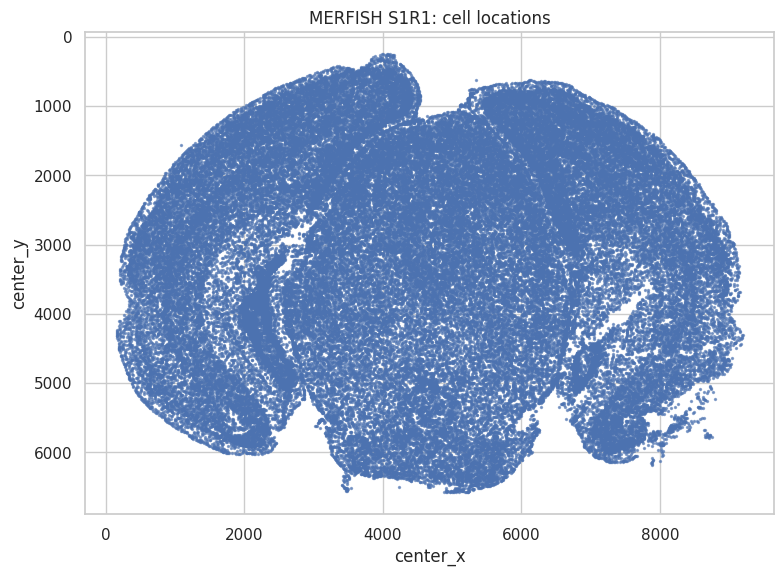

In [33]:
# Basic QC and normalization for downstream analyses.
sc.pp.filter_genes(adata, min_cells=3)
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

# Save the shared input object.
adata.write_h5ad(OUT + "/S1R1_prepared.h5ad")

# Basic tissue-coordinate plot.
xy = adata.obsm["spatial"]
fig, ax = plt.subplots(figsize=(8, 7))
ax.scatter(xy[:, 0], xy[:, 1], s=2, alpha=0.6)
ax.invert_yaxis()
ax.set_aspect("equal")
ax.set_title("MERFISH S1R1: cell locations")
ax.set_xlabel(x_col)
ax.set_ylabel(y_col)
fig.tight_layout()
fig.savefig(OUT + "/01_cell_locations.png", dpi=600)
plt.show()
